In [1]:
# =====================================================
# ⚙️ GPU CONFIGURATION (Balanced Utilization)
# =====================================================
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"   # only GPUs 1 & 2 visible

import os, torch, torch.distributed as dist, torch.multiprocessing as mp
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data.distributed import DistributedSampler
import time, numpy as np, pandas as pd
from tqdm import tqdm


torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("medium")

VISIBLE_GPUS = os.environ["CUDA_VISIBLE_DEVICES"].split(",")
WORLD_SIZE = len(VISIBLE_GPUS)
print(f"🧠 Using GPUs: {VISIBLE_GPUS} ({WORLD_SIZE} total)")



🧠 Using GPUs: ['1'] (1 total)


data laoding

no need to run to load jsu tto split onces


change belwo code later to store folds in 
Results/folds/


In [5]:
# =====================================================
# 📦 Stage1_v2 Data Loading with Weighted Sampling + StratifiedKFold + Test Loader
#    Folds are saved locally to this repo (set SPLIT_VERSION per ablation if you need separate splits)
# =====================================================
import torch, os
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import pandas as pd, numpy as np
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, train_test_split
import nibabel as nib

# --- Paths ---
BASE = Path("/media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/")
PROJECT_ROOT = BASE / "Projects/MutimodelFutureTrends"

# Local fold storage inside this repo; change SPLIT_VERSION per ablation if you want separate folds
LOCAL_PROJECT_ROOT = Path("/home/faizaan/AD/projects/HandlingImbalance")
SPLIT_VERSION = "stage1_v2"  # legacy artifact filename suffix
RESULTS_FOLDER = "Proposed_Model"  # manuscript's proposed hybrid 3D CNN
FOLDS_DIR = LOCAL_PROJECT_ROOT / "folds"  # shared folds for all experiments
FOLDS_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_DIR = LOCAL_PROJECT_ROOT / "Results" / RESULTS_FOLDER
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CUSTOM_CSV = PROJECT_ROOT / "CstomIds_MPRAGE_9_30_2025.csv"
MANIFEST_CSV = PROJECT_ROOT / "manifests/mri_manifest_biascorr.csv"
BIASCORR_DIR = PROJECT_ROOT / "ProcessedNifti_BiasCorr"
RANDOM_SEED = 42

print("📂 Loading CSVs...")
custom_df = pd.read_csv(CUSTOM_CSV)
manifest_df = pd.read_csv(MANIFEST_CSV)

custom_df.rename(columns={"Image Data ID": "ImageID"}, inplace=True)
custom_df["ImageID"] = custom_df["ImageID"].astype(str).str.strip()

def build_biascorr_path(row):
    subj = str(row["Subject"]).strip()
    imgid = str(row["ImageID"]).strip()
    fname = f"{subj}_{imgid}_std.nii.gz"
    full_path = BIASCORR_DIR / fname
    return str(full_path) if full_path.exists() else ""

manifest_df["BiasCorrPath"] = manifest_df.apply(build_biascorr_path, axis=1)
manifest_df = manifest_df[manifest_df["BiasCorrPath"].astype(bool)]

merged = pd.merge(custom_df, manifest_df[["ImageID", "BiasCorrPath"]], on="ImageID", how="inner")
merged["GroupLabel"] = merged["Group"].astype("category").cat.codes
print(f"Total Samples: {len(merged)}")

# Display initial class distribution
print("Initial Class Distribution:")
print(merged["GroupLabel"].value_counts().sort_index())

# --- Dataset ---
class MRIDataset(Dataset):
    def __init__(self, df, path_col, label_col, augment_minority=False):
        self.df = df.reset_index(drop=True)
        self.path_col = path_col
        self.label_col = label_col
        self.augment_minority = augment_minority
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        path = row[self.path_col]
        try:
            img = nib.load(path).get_fdata().astype(np.float32)
            img = np.nan_to_num(img)
            img = (img - np.min(img)) / (np.max(img) - np.min(img) + 1e-8)
            img = torch.from_numpy(img).unsqueeze(0)
            if self.augment_minority and int(row[self.label_col]) == 5:
                img = img + 0.02 * torch.randn_like(img)
                img = torch.clamp(img, 0, 1)
        except Exception as e:
            print(f"⚠️ {path}: {e}")
            img = torch.zeros((1, 128, 128, 128), dtype=torch.float32)
        return {"image": img, "label": torch.tensor(int(row[self.label_col]), dtype=torch.long)}

# --- Global Train/Test split ---
trainval_df, test_df = train_test_split(
    merged, test_size=0.2, random_state=RANDOM_SEED, stratify=merged["GroupLabel"])
print("Test Class Distribution:")
print(test_df["GroupLabel"].value_counts().sort_index())

# --- Stratified 5-Fold Split ---
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
X = np.arange(len(trainval_df))
y = trainval_df["GroupLabel"].values

folds = []
for fold, (train_idx, val_idx) in enumerate(kfold.split(X, y)):
    print(f"===== Fold {fold + 1}/5 =====")
    train_df, val_df = trainval_df.iloc[train_idx], trainval_df.iloc[val_idx]

    print("Train Distribution:")
    print(train_df["GroupLabel"].value_counts().sort_index())
    print("Val Distribution:")
    print(val_df["GroupLabel"].value_counts().sort_index())

    # Weighted sampling instead of oversampling
    class_counts = train_df["GroupLabel"].value_counts().sort_index().values
    class_weights = 1. / torch.tensor(class_counts, dtype=torch.float)
    sample_weights = class_weights[train_df["GroupLabel"].values]
    sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(train_df), replacement=True)

    # Save CSVs locally for reuse across experiments
    fold_dir = FOLDS_DIR / f"fold_{fold+1}"
    fold_dir.mkdir(exist_ok=True)
    train_df.to_csv(fold_dir / "train.csv", index=False)
    val_df.to_csv(fold_dir / "val.csv", index=False)
    test_df.to_csv(fold_dir / "test.csv", index=False)
    print(f"Saved fold {fold+1} CSVs -> {fold_dir}")

    # Create datasets/loaders
    train_ds = MRIDataset(train_df, "BiasCorrPath", "GroupLabel", augment_minority=True)
    val_ds = MRIDataset(val_df, "BiasCorrPath", "GroupLabel")
    test_ds = MRIDataset(test_df, "BiasCorrPath", "GroupLabel")

    train_loader = DataLoader(train_ds, batch_size=4, sampler=sampler, num_workers=2, prefetch_factor=1)
    val_loader = DataLoader(val_ds, batch_size=4, shuffle=False, num_workers=2, prefetch_factor=1)
    test_loader = DataLoader(test_ds, batch_size=4, shuffle=False, num_workers=2, prefetch_factor=1)

    folds.append((train_loader, val_loader, test_loader))

print("✅ Stratified 5-Fold loaders ready with Weighted Sampling and test split.")

📂 Loading CSVs...
Total Samples: 3592
Initial Class Distribution:
GroupLabel
0     405
1     931
2    1091
3     571
4     458
5     136
Name: count, dtype: int64
Test Class Distribution:
GroupLabel
0     81
1    186
2    219
3    114
4     92
5     27
Name: count, dtype: int64
===== Fold 1/5 =====
Train Distribution:
GroupLabel
0    259
1    596
2    697
3    366
4    293
5     87
Name: count, dtype: int64
Val Distribution:
GroupLabel
0     65
1    149
2    175
3     91
4     73
5     22
Name: count, dtype: int64
Saved fold 1 CSVs -> /home/faizaan/AD/projects/HandlingImbalance/folds/fold_1
===== Fold 2/5 =====
Train Distribution:
GroupLabel
0    260
1    596
2    697
3    365
4    293
5     87
Name: count, dtype: int64
Val Distribution:
GroupLabel
0     64
1    149
2    175
3     92
4     73
5     22
Name: count, dtype: int64
Saved fold 2 CSVs -> /home/faizaan/AD/projects/HandlingImbalance/folds/fold_2
===== Fold 3/5 =====
Train Distribution:
GroupLabel
0    259
1    596
2    698
3   

In [13]:
custom_df.head()

,ImageID,Subject,Group,Sex,Age,Visit,Modality,Description,Type,Acq Date,Format,Downloaded
0,I673862,941_S_5193,SMC,F,74,v21,MRI,MPRAGE,Original,4/02/2015,DCM,NaN
1,I374433,941_S_5193,SMC,F,73,v02,MRI,MPRAGE,Original,5/29/2013,DCM,NaN
2,I386070,941_S_5193,SMC,F,73,v04,MRI,MPRAGE,Original,8/19/2013,DCM,NaN
3,I673841,941_S_5124,SMC,F,79,v21,MRI,MPRAGE,Original,4/08/2015,DCM,NaN
4,I420755,941_S_5124,SMC,F,78,v11,MRI,MPRAGE,Original,4/21/2014,DCM,NaN


MODEL

In [3]:
# =====================================================
# 🧠 Stage1_v2 – BetterEfficient3DEncoder with Improved Regularization
# =====================================================
import torch
import torch.nn as nn
from torch.utils.checkpoint import checkpoint
from torchsummary import summary

# =====================================================
# 🔹 Multi-Scale Depthwise Conv Block
# =====================================================
class MultiScaleDWConv3D(nn.Module):
    def __init__(self, in_c, out_c, stride=1, k=3, dilation=2, gn_groups=8):
        super().__init__()
        pad = (k // 2) * dilation
        self.dw = nn.Conv3d(in_c, in_c, k, stride, pad, dilation=dilation, groups=in_c, bias=False)
        self.pw = nn.Conv3d(in_c, out_c, 1, bias=False)
        self.norm = nn.GroupNorm(num_groups=min(gn_groups, out_c), num_channels=out_c)
        self.act = nn.GELU()
    def forward(self, x): 
        return self.act(self.norm(self.pw(self.dw(x))))

# =====================================================
# 🔹 Squeeze-and-Excitation Block
# =====================================================
class SEBlock3D(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool3d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, max(1, channels // reduction)), nn.GELU(),
            nn.Linear(max(1, channels // reduction), channels), nn.Sigmoid()
        )
    def forward(self, x):
        b, c, _, _, _ = x.shape
        w = self.fc(self.pool(x).view(b, c)).view(b, c, 1, 1, 1)
        return x * w

# =====================================================
# 🔹 Stochastic Depth (DropPath)
# =====================================================
class StochasticDepth3D(nn.Module):
    def __init__(self, p=0.0):
        super().__init__()
        self.p = p
    def forward(self, x):
        if not self.training or self.p == 0: 
            return x
        keep = 1 - self.p
        mask = x.new_empty((x.shape[0], 1, 1, 1, 1)).bernoulli_(keep)
        return x * mask / keep

# =====================================================
# 🔹 Improved Residual Block
# =====================================================
class BetterResBlock3D(nn.Module):
    def __init__(self, in_c, out_c, stride=1, se_ratio=0.25, drop_path=0.1, spatial_drop=0.1):
        super().__init__()
        self.use_proj = (stride != 1) or (in_c != out_c)
        self.ms1 = MultiScaleDWConv3D(in_c, out_c, stride=stride, dilation=2)
        self.ms2 = MultiScaleDWConv3D(out_c, out_c)
        self.mlp = nn.Sequential(
            nn.Conv3d(out_c, out_c * 4, 1),
            nn.GELU(),
            nn.Conv3d(out_c * 4, out_c, 1),
            nn.Dropout3d(spatial_drop)
        )
        self.se = SEBlock3D(out_c, reduction=max(1, int(out_c * se_ratio)))
        self.drop = StochasticDepth3D(drop_path)
        self.proj = nn.Conv3d(in_c, out_c, 1, stride=stride, bias=False) if self.use_proj else nn.Identity()

    def forward(self, x):
        idn = self.proj(x)
        x = self.ms2(self.ms1(x))
        x = self.mlp(x)
        x = self.se(x)
        x = self.drop(x)
        return idn + x

# =====================================================
# 🔹 Full Encoder Model
# =====================================================
class BetterEfficient3DEncoder(nn.Module):
    def __init__(self, in_channels=1, base_channels=32, num_classes=6, drop_path_rate=0.2, spatial_drop=0.1):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv3d(in_channels, base_channels, 3, 2, 1, bias=False),
            nn.GroupNorm(num_groups=min(8, base_channels), num_channels=base_channels),
            nn.GELU()
        )

        widths = [base_channels, base_channels*2, base_channels*4, base_channels*8]
        strides = [1, 2, 2, 2]
        n_blocks = [2, 2, 2, 3]
        total_blocks = sum(n_blocks)
        dp_rates = torch.linspace(0.05, drop_path_rate, total_blocks).tolist()

        blocks = []
        in_c = widths[0]
        idx = 0
        for i, (out_c, s, nb) in enumerate(zip(widths, strides, n_blocks)):
            for j in range(nb):
                blocks.append(
                    BetterResBlock3D(
                        in_c, out_c,
                        stride=s if j == 0 else 1,
                        drop_path=dp_rates[idx],
                        spatial_drop=spatial_drop
                    )
                )
                in_c = out_c
                idx += 1

        self.encoder = nn.Sequential(*blocks)
        self.encoder_dropout = nn.Dropout3d(0.05)  # global encoder regularization
        self.gap, self.gmp = nn.AdaptiveAvgPool3d(1), nn.AdaptiveMaxPool3d(1)

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(widths[-1]*2, widths[-1]), nn.GELU(),
            nn.Dropout(0.20),
            nn.Linear(widths[-1], widths[-1]//2), nn.GELU(),
            nn.Dropout(0.20),
            nn.Linear(widths[-1]//2, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.encoder(x)
        x = self.encoder_dropout(x)
        feat = torch.cat([self.gap(x), self.gmp(x)], 1)
        return self.classifier(feat)

# =====================================================
# ✅ Summary
# =====================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = BetterEfficient3DEncoder(in_channels=1, base_channels=32, num_classes=6).to(device)
summary(model, input_size=(1, 128, 128, 128), batch_size=2)


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv3d-1        [2, 32, 64, 64, 64]             864
         GroupNorm-2        [2, 32, 64, 64, 64]              64
              GELU-3        [2, 32, 64, 64, 64]               0
          Identity-4        [2, 32, 64, 64, 64]               0
            Conv3d-5        [2, 32, 64, 64, 64]             864
            Conv3d-6        [2, 32, 64, 64, 64]           1,024
         GroupNorm-7        [2, 32, 64, 64, 64]              64
              GELU-8        [2, 32, 64, 64, 64]               0
MultiScaleDWConv3D-9        [2, 32, 64, 64, 64]               0
           Conv3d-10        [2, 32, 64, 64, 64]             864
           Conv3d-11        [2, 32, 64, 64, 64]           1,024
        GroupNorm-12        [2, 32, 64, 64, 64]              64
             GELU-13        [2, 32, 64, 64, 64]               0
MultiScaleDWConv3D-14        [2, 32, 64

#### Testing code for training

##### A

In [6]:
# =====================================================
# 🏋️ Training Loop (Stage1_v2, cleaned & fixed)
#  - No in-training temperature scaling
#  - Correct torchmetrics usage (update/compute, per phase/epoch)
#  - AUC uses probabilities
#  - Per-fold class weights from training labels
#  - New filenames: best_model_stage1v2.pt, history_stage1v2.csv
# =====================================================
from tqdm.auto import tqdm  # works in notebook + script

import time, numpy as np, pandas as pd, torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torchmetrics.classification import (
    MulticlassAccuracy, MulticlassF1Score,
    MulticlassPrecision, MulticlassRecall, MulticlassAUROC
)
from sklearn.utils.class_weight import compute_class_weight

# --- Focal + Label-Smoothed Loss ---
class FocalLossLS(nn.Module):
    def __init__(self, weight=None, gamma=2.0, smoothing=0.05):
        super().__init__()
        self.weight = weight
        self.gamma = gamma
        self.smoothing = smoothing

    def forward(self, logits, target):
        logp = F.log_softmax(logits, dim=1)
        p = torch.exp(logp)
        ncls = logits.size(1)

        with torch.no_grad():
            true = torch.zeros_like(logp)
            true.fill_(self.smoothing / (ncls - 1))
            true.scatter_(1, target.unsqueeze(1), 1 - self.smoothing)

        ce = -(true * logp)              # label-smoothed CE
        focal = ((1 - p) ** self.gamma) * ce  # focal modulation

        if self.weight is not None:
            focal = focal * self.weight[target].unsqueeze(1)

        return focal.sum(1).mean()


# --- Training Function ---
def train_fold(fold_id, train_loader, val_loader, RESULTS_DIR):
    print(f"\n🧩 Training Fold {fold_id}")
    num_classes = 6
    model = BetterEfficient3DEncoder(num_classes=num_classes).to(device)

    # Compute class weights from this fold's training labels
    try:
        train_labels = train_loader.dataset.df["GroupLabel"].to_numpy()
        cls_w = compute_class_weight(
            class_weight="balanced",
            classes=np.arange(num_classes),
            y=train_labels
        )
        cls_w = torch.tensor(cls_w, dtype=torch.float32, device=device)
    except Exception as e:
        print(f"⚠️ Class weight computation fell back to uniform: {e}")
        cls_w = torch.ones(num_classes, device=device)

    criterion = FocalLossLS(weight=cls_w, gamma=2.0, smoothing=0.05)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=1/3, patience=3, verbose=True)
    scaler = torch.amp.GradScaler(device="cuda")

    # Base metric definitions (fresh clones per epoch/phase)
    base_metrics = {
        "acc":  MulticlassAccuracy(num_classes=num_classes, average="macro"),
        "f1":   MulticlassF1Score(num_classes=num_classes, average="macro"),
        "prec": MulticlassPrecision(num_classes=num_classes, average="macro"),
        "rec":  MulticlassRecall(num_classes=num_classes, average="macro"),
        "auc":  MulticlassAUROC(num_classes=num_classes, average="macro"),
    }

    best_val, no_imp = np.inf, 0
    early_stop, wd_factor = 7, 3

    fold_dir = RESULTS_DIR / f"fold_{fold_id}"
    fold_dir.mkdir(exist_ok=True)
    best_path = fold_dir / "best_model_stage1v2.pt"
    hist = []

    for ep in range(1, 251):
        start = time.time()
        model.train()
        train_loss = 0.0
        # fresh metrics for TRAIN
        train_metrics = {k: m.clone().to(device) for k, m in base_metrics.items()}

        # --- TRAIN ---
        for b in tqdm(train_loader, desc=f"[Fold {fold_id}] Epoch {ep} (Train)", ncols=800):
            imgs = b["image"].to(device)
            lbl  = b["label"].to(device)

            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(imgs)
                loss   = criterion(logits, lbl)
                probs  = torch.softmax(logits, dim=1)  # for AUC

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item() * imgs.size(0)

            # update metrics
            for name, m in train_metrics.items():
                preds = probs if name == "auc" else logits
                m.update(preds, lbl)

        ntr = len(train_loader.dataset)
        train_loss /= ntr
        tr_avg = {name: m.compute().item() for name, m in train_metrics.items()}

        # --- VALIDATION ---
        model.eval()
        val_loss = 0.0
        # fresh metrics for VAL
        val_metrics = {k: m.clone().to(device) for k, m in base_metrics.items()}

        with torch.no_grad():
            for b in tqdm(val_loader, desc=f"[Fold {fold_id}] Epoch {ep} (Val)", ncols=800):
                imgs = b["image"].to(device)
                lbl  = b["label"].to(device)

                with torch.amp.autocast(device_type="cuda", dtype=torch.float16):
                    logits = model(imgs)
                    loss   = criterion(logits, lbl)
                    probs  = torch.softmax(logits, dim=1)

                val_loss += loss.item() * imgs.size(0)

                for name, m in val_metrics.items():
                    preds = probs if name == "auc" else logits
                    m.update(preds, lbl)

        nval = len(val_loader.dataset)
        val_loss /= nval
        vl_avg = {name: m.compute().item() for name, m in val_metrics.items()}

        scheduler.step(val_loss)

        # Dynamic Weight Decay
        if val_loss > best_val:
            optimizer.param_groups[0]["weight_decay"] *= wd_factor

        print(
            f"Epoch {ep:03d} | TL {train_loss:.4f} | VL {val_loss:.4f} | "
            f"Acc {tr_avg['acc']:.3f}/{vl_avg['acc']:.3f} | "
            f"F1 {tr_avg['f1']:.3f}/{vl_avg['f1']:.3f} | "
            f"AUC {tr_avg['auc']:.3f}/{vl_avg['auc']:.3f} | "
            f"LR {optimizer.param_groups[0]['lr']:.2e} | "
            f"{(time.time() - start)/60:.2f} min"
        )

        # log for this epoch
        hist.append([
            ep,
            train_loss,
            val_loss,
            tr_avg.copy(),
            vl_avg.copy(),
        ])

        # checkpointing
        if val_loss < best_val:
            best_val, no_imp = val_loss, 0
            torch.save(model.state_dict(), best_path)
        else:
            no_imp += 1
            if no_imp >= early_stop:
                print(f"🛑 Early stopping triggered at epoch {ep}.")
                break

    # Save history to CSV (stage1_v2 name to distinguish from older runs)
    hist_rows = []
    for e, tl, vl, tr_dict, vl_dict in hist:
        row = {
            "epoch": e,
            "train_loss": tl,
            "val_loss": vl,
        }
        for k, v in tr_dict.items():
            row[f"train_{k}"] = v
        for k, v in vl_dict.items():
            row[f"val_{k}"] = v
        hist_rows.append(row)

    hist_df = pd.DataFrame(hist_rows)
    hist_path = fold_dir / "history_stage1v2.csv"
    hist_df.to_csv(hist_path, index=False)
    print(f"✅ Fold {fold_id} finished. Best model saved → {best_path}")
    print(f"📊 History saved → {hist_path}")


In [7]:
# =====================================================
# 🚀 Run 5-Fold Training (Stage1_A, using Results/fold splits)
# =====================================================
from pathlib import Path
from torch.utils.data import DataLoader
import torch.multiprocessing as mp


# Where the precomputed splits live
SPLIT_DIR   = FOLDS_DIR      # <-- you said you put all fold_* here
# Where to save this experiment's outputs
RESULTS_DIR = LOCAL_PROJECT_ROOT / "Results" / RESULTS_FOLDER
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

for fold_idx in range(1, 6):
    split_fold_dir = SPLIT_DIR / f"fold_{fold_idx}"
    if not split_fold_dir.exists():
        raise FileNotFoundError(
            f"{split_fold_dir} does not exist. "
            f"Expected train.csv / val.csv / test.csv in Results/fold/fold_{fold_idx}."
        )

    # Load per-fold splits
    train_df = pd.read_csv(split_fold_dir / "train.csv")
    val_df   = pd.read_csv(split_fold_dir / "val.csv")
    # test_df is global or used later for evaluation

    # Datasets and loaders
    train_ds = MRIDataset(train_df, "BiasCorrPath", "GroupLabel")
    val_ds   = MRIDataset(val_df,   "BiasCorrPath", "GroupLabel")

    train_loader = DataLoader(train_ds, batch_size=4, shuffle=True,
                          num_workers=2, persistent_workers=True, prefetch_factor=1)
    val_loader   = DataLoader(val_ds, batch_size=4, shuffle=False,
                          num_workers=2, persistent_workers=True, prefetch_factor=1)

    # train_fold internally saves to RESULTS_DIR / f"fold_{fold_id}"
    train_fold(fold_idx, train_loader, val_loader, RESULTS_DIR)

print("✅ All folds (Stage1_A) completed.")



🧩 Training Fold 1


/home/faizaan/miniconda3/envs/mlenv/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


[Fold 1] Epoch 1 (Train):   0%|                                                                               …

[Fold 1] Epoch 1 (Val):   0%|                                                                                 …

Epoch 001 | TL 1.2527 | VL 1.2455 | Acc 0.163/0.167 | F1 0.155/0.069 | AUC 0.490/0.666 | LR 1.00e-04 | 1.55 min


[Fold 1] Epoch 2 (Train):   0%|                                                                               …

... (505 outputs left out)

Epoch 038 | TL 1.2443 | VL 1.2467 | Acc 0.161/0.167 | F1 0.082/0.078 | AUC 0.483/0.500 | LR 1.11e-05 | 1.45 min


[Fold 5] Epoch 39 (Train):   0%|                                                                              …

[Fold 5] Epoch 39 (Val):   0%|                                                                                …

Epoch 039 | TL 1.2443 | VL 1.2467 | Acc 0.162/0.167 | F1 0.138/0.012 | AUC 0.476/0.500 | LR 1.11e-05 | 1.47 min
🛑 Early stopping triggered at epoch 39.
✅ Fold 5 finished. Best model saved → /home/faizaan/AD/projects/HandlingImbalance/Results/stage1_v2/fold_5/best_model_stage1v2.pt
📊 History saved → /home/faizaan/AD/projects/HandlingImbalance/Results/stage1_v2/fold_5/history_stage1v2.csv
✅ All folds (Stage1_A) completed.


classification detailed train, validation ,test


############################
### Fold 1 Evaluation
############################

===== Fold 1 - Train Metrics =====
Accuracy  : 0.9956
Macro F1  : 0.9965
Macro Prec: 0.9957
Macro Rec : 0.9973
Macro AUC : 1.0000

Classification Report:
              precision    recall  f1-score   support

          AD     1.0000    1.0000    1.0000       259
          CN     0.9983    1.0000    0.9992       596
        EMCI     1.0000    0.9871    0.9935       697
        LMCI     0.9760    1.0000    0.9879       366
         MCI     1.0000    0.9966    0.9983       293
         SMC     1.0000    1.0000    1.0000        87

    accuracy                         0.9956      2298
   macro avg     0.9957    0.9973    0.9965      2298
weighted avg     0.9957    0.9956    0.9957      2298


===== Fold 1 - Val Metrics =====
Accuracy  : 0.9043
Macro F1  : 0.8979
Macro Prec: 0.9041
Macro Rec : 0.8937
Macro AUC : 0.9723

Classification Report:
              precision    recall  f1-score   support

          AD 

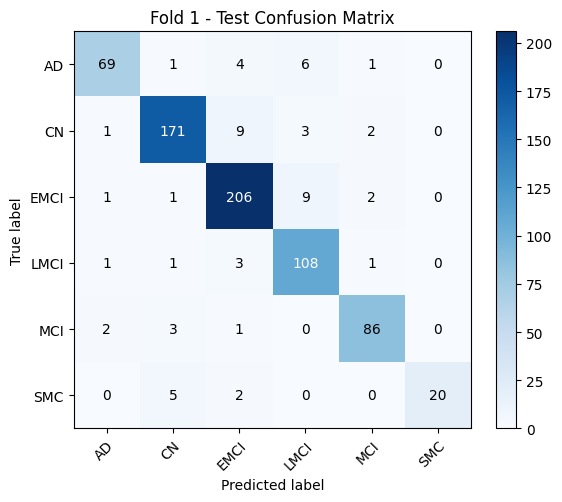


############################
### Fold 2 Evaluation
############################

===== Fold 2 - Train Metrics =====
Accuracy  : 0.9996
Macro F1  : 0.9996
Macro Prec: 0.9994
Macro Rec : 0.9998
Macro AUC : 1.0000

Classification Report:
              precision    recall  f1-score   support

          AD     1.0000    1.0000    1.0000       260
          CN     1.0000    1.0000    1.0000       596
        EMCI     1.0000    0.9986    0.9993       697
        LMCI     1.0000    1.0000    1.0000       365
         MCI     0.9966    1.0000    0.9983       293
         SMC     1.0000    1.0000    1.0000        87

    accuracy                         0.9996      2298
   macro avg     0.9994    0.9998    0.9996      2298
weighted avg     0.9996    0.9996    0.9996      2298


===== Fold 2 - Val Metrics =====
Accuracy  : 0.9426
Macro F1  : 0.9216
Macro Prec: 0.9365
Macro Rec : 0.9107
Macro AUC : 0.9700

Classification Report:
              precision    recall  f1-score   support

          AD 

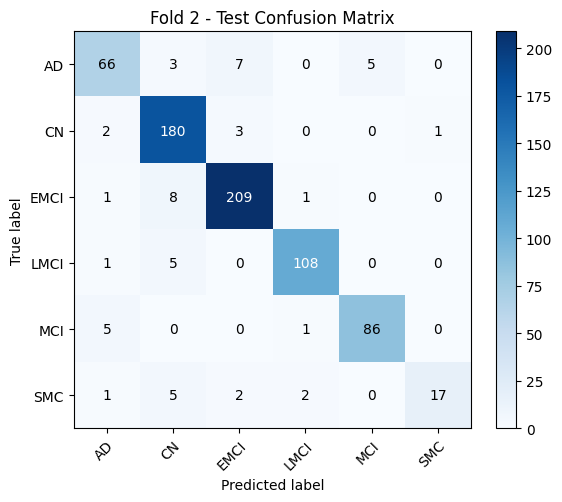


############################
### Fold 3 Evaluation
############################

===== Fold 3 - Train Metrics =====
Accuracy  : 0.9639
Macro F1  : 0.9633
Macro Prec: 0.9515
Macro Rec : 0.9785
Macro AUC : 0.9983

Classification Report:
              precision    recall  f1-score   support

          AD     0.9846    0.9884    0.9865       259
          CN     0.9255    0.9799    0.9519       596
        EMCI     0.9968    0.9026    0.9474       698
        LMCI     0.9838    1.0000    0.9918       365
         MCI     0.9734    1.0000    0.9865       293
         SMC     0.8447    1.0000    0.9158        87

    accuracy                         0.9639      2298
   macro avg     0.9515    0.9785    0.9633      2298
weighted avg     0.9661    0.9639    0.9638      2298


===== Fold 3 - Val Metrics =====
Accuracy  : 0.8139
Macro F1  : 0.8027
Macro Prec: 0.8010
Macro Rec : 0.8211
Macro AUC : 0.9398

Classification Report:
              precision    recall  f1-score   support

          AD 

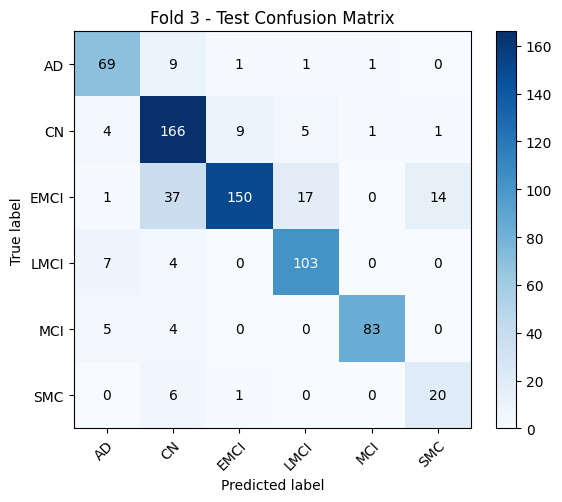


############################
### Fold 4 Evaluation
############################

===== Fold 4 - Train Metrics =====
Accuracy  : 1.0000
Macro F1  : 1.0000
Macro Prec: 1.0000
Macro Rec : 1.0000
Macro AUC : 1.0000

Classification Report:
              precision    recall  f1-score   support

          AD     1.0000    1.0000    1.0000       259
          CN     1.0000    1.0000    1.0000       596
        EMCI     1.0000    1.0000    1.0000       698
        LMCI     1.0000    1.0000    1.0000       366
         MCI     1.0000    1.0000    1.0000       292
         SMC     1.0000    1.0000    1.0000        88

    accuracy                         1.0000      2299
   macro avg     1.0000    1.0000    1.0000      2299
weighted avg     1.0000    1.0000    1.0000      2299


===== Fold 4 - Val Metrics =====
Accuracy  : 0.9199
Macro F1  : 0.9074
Macro Prec: 0.9201
Macro Rec : 0.8967
Macro AUC : 0.9657

Classification Report:
              precision    recall  f1-score   support

          AD 

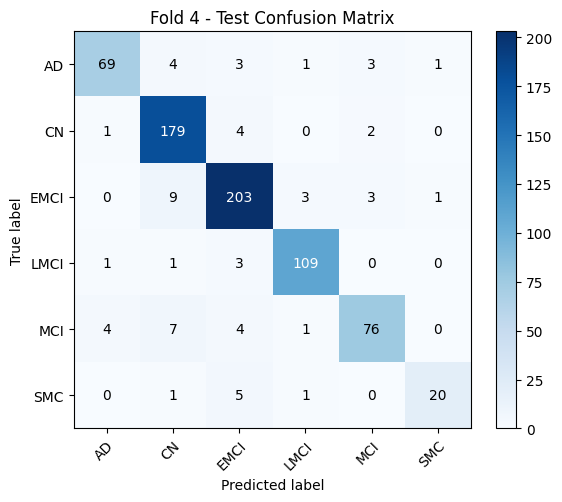


############################
### Fold 5 Evaluation
############################

===== Fold 5 - Train Metrics =====
Accuracy  : 0.9996
Macro F1  : 0.9996
Macro Prec: 0.9994
Macro Rec : 0.9998
Macro AUC : 1.0000

Classification Report:
              precision    recall  f1-score   support

          AD     1.0000    1.0000    1.0000       259
          CN     1.0000    1.0000    1.0000       596
        EMCI     1.0000    0.9986    0.9993       698
        LMCI     1.0000    1.0000    1.0000       366
         MCI     0.9966    1.0000    0.9983       293
         SMC     1.0000    1.0000    1.0000        87

    accuracy                         0.9996      2299
   macro avg     0.9994    0.9998    0.9996      2299
weighted avg     0.9996    0.9996    0.9996      2299


===== Fold 5 - Val Metrics =====
Accuracy  : 0.9303
Macro F1  : 0.9043
Macro Prec: 0.9367
Macro Rec : 0.8906
Macro AUC : 0.9565

Classification Report:
              precision    recall  f1-score   support

          AD 

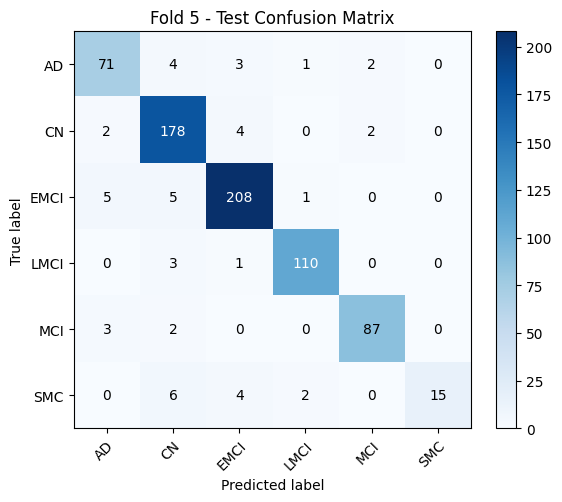


===== Mean Test Metrics Across Folds =====
Acc  : 0.9018 ± 0.0404
F1   : 0.8804 ± 0.0352
AUC  : 0.9463 ± 0.0050


/tmp/ipykernel_1395062/1350541056.py:180: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


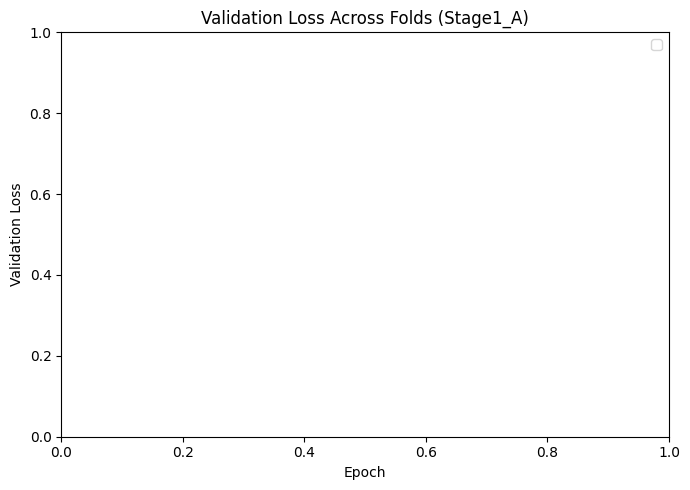

In [8]:
# 🧪 Evaluation: Train / Val / Test + Plots (Stage1_A)
# =====================================================
import numpy as np, pandas as pd, torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score
)
import matplotlib.pyplot as plt

# --- Label mapping (must match training) ---
label_map    = {'AD':0, 'CN':1, 'EMCI':2, 'LMCI':3, 'MCI':4, 'SMC':5}
idx_to_label = {v: k for k, v in label_map.items()}
class_names  = [idx_to_label[i] for i in range(len(label_map))]

# --- Paths ---
SPLIT_DIR   = FOLDS_DIR       # where train/val/test CSVs live
RESULTS_DIR = LOCAL_PROJECT_ROOT / "Results" / RESULTS_FOLDER

def evaluate_split(model, loader, split_name=""):
    model.eval()
    all_logits, all_probs, all_labels = [], [], []

    with torch.no_grad():
        for b in loader:
            imgs = b["image"].to(device)
            lbl  = b["label"].to(device)

            with torch.amp.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(imgs)
                probs  = torch.softmax(logits, dim=1)

            all_logits.append(logits.cpu())
            all_probs.append(probs.cpu())
            all_labels.append(lbl.cpu())

    all_logits = torch.cat(all_logits, dim=0).numpy()
    all_probs  = torch.cat(all_probs,  dim=0).numpy()
    all_labels = torch.cat(all_labels, dim=0).numpy()
    preds      = all_probs.argmax(axis=1)

    acc  = accuracy_score(all_labels, preds)
    f1   = f1_score(all_labels, preds, average="macro")
    prec = precision_score(all_labels, preds, average="macro")
    rec  = recall_score(all_labels, preds, average="macro")

    # Macro AUC (OvR)
    try:
        auc_macro = roc_auc_score(all_labels, all_probs,
                                  multi_class="ovr", average="macro")
    except ValueError:
        auc_macro = np.nan

    print(f"\n===== {split_name} Metrics =====")
    print(f"Accuracy  : {acc:.4f}")
    print(f"Macro F1  : {f1:.4f}")
    print(f"Macro Prec: {prec:.4f}")
    print(f"Macro Rec : {rec:.4f}")
    print(f"Macro AUC : {auc_macro:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        all_labels, preds,
        target_names=class_names,
        digits=4
    ))

    cm = confusion_matrix(all_labels, preds, labels=list(range(len(class_names))))
    return {
        "acc": acc, "f1": f1, "prec": prec, "rec": rec,
        "auc": auc_macro, "cm": cm,
        "y_true": all_labels, "y_pred": preds
    }


def plot_confusion_matrix(cm, class_names, title):
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    ax.figure.colorbar(im, ax=ax)
    ax.set(
        xticks=np.arange(len(class_names)),
        yticks=np.arange(len(class_names)),
        xticklabels=class_names,
        yticklabels=class_names,
        ylabel="True label",
        xlabel="Predicted label",
        title=title,
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j, i, format(cm[i, j], "d"),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black"
            )

    fig.tight_layout()
    plt.show()


# ---- Evaluate each fold on train/val/test & plot histories ----
all_fold_results = []

for fold_idx in range(1, 6):
    print(f"\n############################")
    print(f"### Fold {fold_idx} Evaluation")
    print(f"############################")

    # Paths for this fold
    split_fold_dir  = SPLIT_DIR   / f"fold_{fold_idx}"   # CSVs
    result_fold_dir = RESULTS_DIR / f"fold_{fold_idx}"   # model + history

    # --- Load data splits (correct paths) ---
    train_df = pd.read_csv(split_fold_dir / "train.csv")
    val_df   = pd.read_csv(split_fold_dir / "val.csv")
    test_df  = pd.read_csv(split_fold_dir / "test.csv")

    train_ds = MRIDataset(train_df, "BiasCorrPath", "GroupLabel")
    val_ds   = MRIDataset(val_df,   "BiasCorrPath", "GroupLabel")
    test_ds  = MRIDataset(test_df,  "BiasCorrPath", "GroupLabel")

    train_loader = DataLoader(train_ds, batch_size=2, shuffle=False,
                              num_workers=2, prefetch_factor=1)
    val_loader   = DataLoader(val_ds,   batch_size=2, shuffle=False,
                              num_workers=2, prefetch_factor=1)
    test_loader  = DataLoader(test_ds,  batch_size=2, shuffle=False,
                              num_workers=2, prefetch_factor=1)

    # --- Load best model for this fold ---
    model = BetterEfficient3DEncoder(num_classes=len(label_map)).to(device)

    # Adjust this name to match your training loop save-name
    best_path = result_fold_dir / "best_model_stage1v2.pt"
    state = torch.load(best_path, map_location=device)
    model.load_state_dict(state)

    # --- Evaluate ---
    res_train = evaluate_split(model, train_loader, split_name=f"Fold {fold_idx} - Train")
    res_val   = evaluate_split(model, val_loader,   split_name=f"Fold {fold_idx} - Val")
    res_test  = evaluate_split(model, test_loader,  split_name=f"Fold {fold_idx} - Test")

    # --- Plot confusion matrix for test split ---
    plot_confusion_matrix(
        res_test["cm"], class_names,
        title=f"Fold {fold_idx} - Test Confusion Matrix"
    )

    all_fold_results.append({
        "fold": fold_idx,
        "train": res_train,
        "val": res_val,
        "test": res_test,
    })

# ---- Aggregate test metrics across folds ----
test_accs = [fr["test"]["acc"]  for fr in all_fold_results]
test_f1s  = [fr["test"]["f1"]   for fr in all_fold_results]
test_aucs = [fr["test"]["auc"]  for fr in all_fold_results]

print("\n===== Mean Test Metrics Across Folds =====")
print(f"Acc  : {np.mean(test_accs):.4f} ± {np.std(test_accs):.4f}")
print(f"F1   : {np.mean(test_f1s):.4f} ± {np.std(test_f1s):.4f}")
print(f"AUC  : {np.nanmean(test_aucs):.4f} ± {np.nanstd(test_aucs):.4f}")  # handle NaN if any

# ---- Plot validation loss histories for all folds ----
plt.figure(figsize=(7, 5))
for fold_idx in range(1, 6):
    hist_path = RESULTS_DIR / f"fold_{fold_idx}" / f"history_{SPLIT_VERSION}.csv"
    if not hist_path.exists():
        continue
    df_hist = pd.read_csv(hist_path)
    plt.plot(df_hist["epoch"], df_hist["val_loss"], label=f"Fold {fold_idx}")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title(f"Validation Loss Across Folds ({SPLIT_VERSION})")
plt.legend()
plt.tight_layout()
plt.show()

import matplotlib.pyplot as plt
RESULTS_DIR = LOCAL_PROJECT_ROOT / "Results" / RESULTS_FOLDER
plt.figure(figsize=(7, 5))
for fold_idx in range(1, 6):
    hist_path = RESULTS_DIR / f"fold_{fold_idx}" / f"history_{SPLIT_VERSION}.csv"
    df_hist = pd.read_csv(hist_path)
    plt.plot(df_hist["epoch"], df_hist["val_loss"], label=f"Fold {fold_idx}")

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title(f"Validation Loss Across Folds ({SPLIT_VERSION})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Classification test MEAN of all 5

Results Directory: /home/faizaan/AD/projects/HandlingImbalance/Results/stage1_v2
  -> Fold 1
  -> Fold 2
  -> Fold 3
  -> Fold 4
  -> Fold 5

===== 📊 Mean Test Metrics Across Folds =====
Accuracy  : 0.9018
Macro F1  : 0.8804
Macro Prec: 0.9035
Macro Rec : 0.8691
Macro AUC : 0.9463

===== 📊 Mean Test Classification Report Across Folds =====
       label  precision   recall  f1-score  support
          AD   0.879944 0.849383  0.863719     81.0
          CN   0.871827 0.939785  0.903511    186.0
        EMCI   0.930561 0.891324  0.907129    219.0
        LMCI   0.910325 0.943860  0.926193    114.0
         MCI   0.943423 0.908696  0.925396     92.0
         SMC   0.884993 0.681481  0.756479     27.0
    accuracy   0.901808 0.901808  0.901808      NaN
   macro avg   0.903512 0.869088  0.880404    719.0
weighted avg   0.906391 0.901808  0.901005    719.0


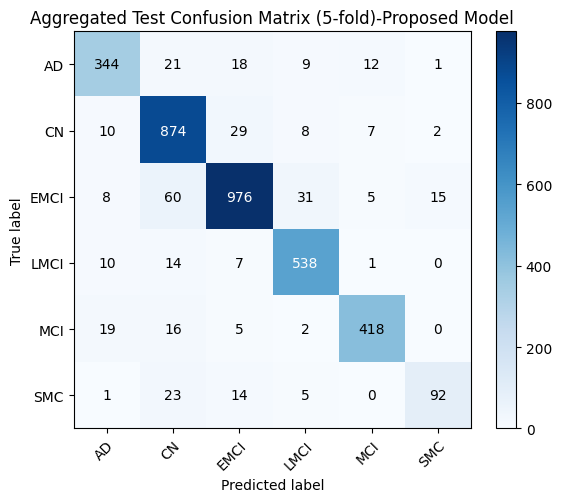

In [24]:
# =====================================================
# 📊 Mean Test Metrics + Mean Classification Report + Confusion Matrix
# =====================================================
import numpy as np, pandas as pd, torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score
)
import matplotlib.pyplot as plt
from pathlib import Path

# --- Label mapping (same as training) ---
label_map    = {'AD':0, 'CN':1, 'EMCI':2, 'LMCI':3, 'MCI':4, 'SMC':5}
idx_to_label = {v: k for k, v in label_map.items()}
class_names  = [idx_to_label[i] for i in range(len(label_map))]

# --- Paths ---
SPLIT_DIR    = FOLDS_DIR      # train/val/test CSVs
RESULTS_DIR = LOCAL_PROJECT_ROOT / "Results" / RESULTS_FOLDER
print(f"Results Directory: {RESULTS_DIR}")
# Change if your filename differs
MODEL_FILENAME = "best_model_stage1v2.pt"

# Storage
per_fold_reports   = []
per_fold_metrics   = []   # scalar metrics
overall_cm         = np.zeros((len(class_names), len(class_names)), dtype=int)

print("Collecting test predictions for all folds...")

for fold_idx in range(1, 6):
    print(f"  -> Fold {fold_idx}")
    split_fold_dir  = SPLIT_DIR   / f"fold_{fold_idx}"
    result_fold_dir = RESULTS_DIR / f"fold_{fold_idx}"

    # --- Load test split ---
    test_df = pd.read_csv(split_fold_dir / "test.csv")
    test_ds = MRIDataset(test_df, "BiasCorrPath", "GroupLabel")
    test_loader = DataLoader(test_ds, batch_size=2, shuffle=False,
                             num_workers=2, prefetch_factor=1)

    # --- Load model ---
    model = BetterEfficient3DEncoder(num_classes=len(label_map)).to(device)
    best_path = result_fold_dir / MODEL_FILENAME
    state = torch.load(best_path, map_location=device)

    # handle possible {"model": ..., "temperature": ...} or plain state_dict
    if isinstance(state, dict) and "model" in state:
        model.load_state_dict(state["model"])
    else:
        model.load_state_dict(state)

    # --- Collect predictions (logits, probs, labels) ---
    model.eval()
    all_labels, all_preds, all_probs = [], [], []

    with torch.no_grad():
        for b in test_loader:
            imgs = b["image"].to(device)
            lbl  = b["label"].to(device)

            with torch.amp.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(imgs)
                probs  = torch.softmax(logits, dim=1)

            pred = probs.argmax(dim=1)

            all_labels.append(lbl.cpu())
            all_preds.append(pred.cpu())
            all_probs.append(probs.cpu())

    all_labels = torch.cat(all_labels, dim=0).numpy()
    all_preds  = torch.cat(all_preds,  dim=0).numpy()
    all_probs  = torch.cat(all_probs,  dim=0).numpy()

    # --- Scalar metrics for this fold ---
    acc  = accuracy_score(all_labels, all_preds)
    f1   = f1_score(all_labels, all_preds, average="macro")
    prec = precision_score(all_labels, all_preds, average="macro")
    rec  = recall_score(all_labels, all_preds, average="macro")
    try:
        auc_macro = roc_auc_score(all_labels, all_probs,
                                  multi_class="ovr", average="macro")
    except ValueError:
        auc_macro = np.nan

    per_fold_metrics.append({
        "fold": fold_idx,
        "acc": acc,
        "f1": f1,
        "prec": prec,
        "rec": rec,
        "auc": auc_macro
    })

    # --- Classification report dict for this fold ---
    rep = classification_report(
        all_labels,
        all_preds,
        target_names=class_names,
        output_dict=True,
        digits=4,
    )
    per_fold_reports.append(rep)

    # --- Update overall confusion matrix (sum over folds) ---
    cm = confusion_matrix(all_labels, all_preds,
                          labels=list(range(len(class_names))))
    overall_cm += cm

# ---------- Save all per-fold test metrics ----------
metrics_df = pd.DataFrame(per_fold_metrics)
metrics_df.to_csv(RESULTS_DIR / "test_metrics_all_folds.csv", index=False)

# ---------- 1) Mean scalar test metrics ----------
metrics_df = pd.DataFrame(per_fold_metrics)

mean_acc  = metrics_df["acc"].mean()
mean_f1   = metrics_df["f1"].mean()
mean_prec = metrics_df["prec"].mean()
mean_rec  = metrics_df["rec"].mean()
mean_auc  = metrics_df["auc"].mean()

print("\n===== 📊 Mean Test Metrics Across Folds =====")
print(f"Accuracy  : {mean_acc:.4f}")
print(f"Macro F1  : {mean_f1:.4f}")
print(f"Macro Prec: {mean_prec:.4f}")
print(f"Macro Rec : {mean_rec:.4f}")
print(f"Macro AUC : {mean_auc:.4f}")

# ---------- 2) Mean test classification report ----------
records = []
for rep in per_fold_reports:
    for label, stats in rep.items():
        if label == "accuracy":
            records.append({
                "label": "accuracy",
                "precision": stats,
                "recall":    stats,
                "f1-score":  stats,
                "support":   np.nan,
            })
        else:
            records.append({
                "label": label,
                "precision": stats["precision"],
                "recall":    stats["recall"],
                "f1-score":  stats["f1-score"],
                "support":   stats["support"],
            })

df_reports = pd.DataFrame(records)

mean_report = df_reports.groupby("label", as_index=False).mean(numeric_only=True)

order = list(class_names) + ["accuracy", "macro avg", "weighted avg"]
mean_report["label"] = pd.Categorical(mean_report["label"],
                                      categories=order, ordered=True)
mean_report = mean_report.sort_values("label")

print("\n===== 📊 Mean Test Classification Report Across Folds =====")
print(mean_report.to_string(index=False))

# ---------- 3) Plot aggregated test confusion matrix ----------
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(overall_cm, interpolation="nearest", cmap="Blues")
ax.figure.colorbar(im, ax=ax)
ax.set(
    xticks=np.arange(len(class_names)),
    yticks=np.arange(len(class_names)),
    xticklabels=class_names,
    yticklabels=class_names,
    ylabel="True label",
    xlabel="Predicted label",
    title="Aggregated Test Confusion Matrix (5-fold)-Proposed Model",
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

thresh = overall_cm.max() / 2.0
for i in range(overall_cm.shape[0]):
    for j in range(overall_cm.shape[1]):
        ax.text(
            j, i, format(overall_cm[i, j], "d"),
            ha="center", va="center",
            color="white" if overall_cm[i, j] > thresh else "black"
        )

fig.tight_layout()
plt.show()


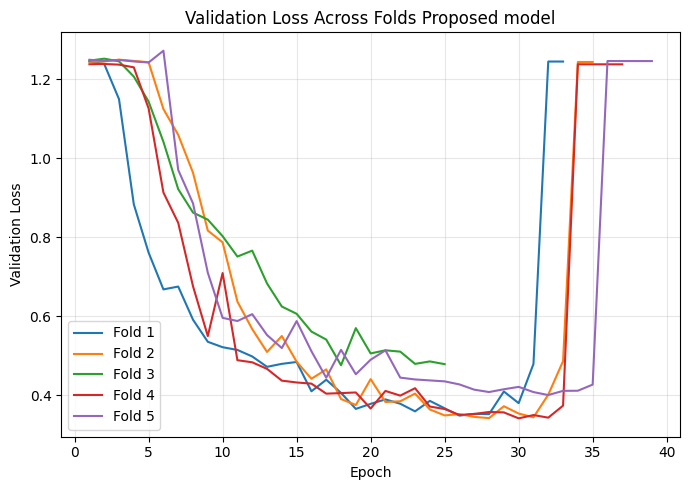

Results Directory: /home/faizaan/AD/projects/HandlingImbalance/Results/stage1_v2


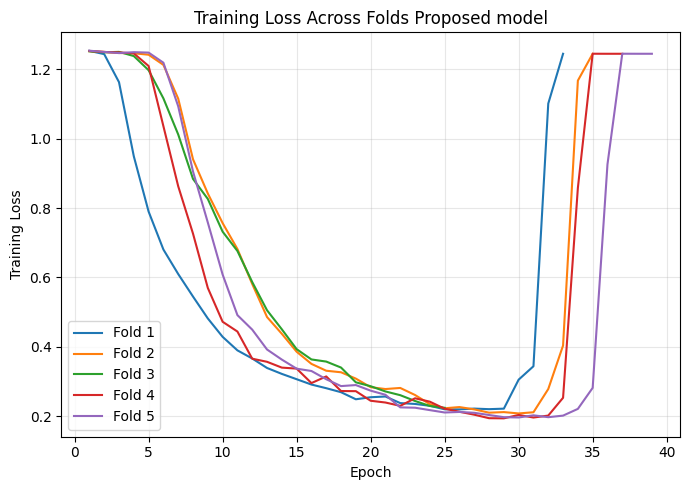

In [23]:
# =====================================================
# 📉 Plot Validation Loss Across Folds (Stage1_v2)
# =====================================================
import matplotlib.pyplot as plt

RESULTS_DIR = LOCAL_PROJECT_ROOT / "Results" / RESULTS_FOLDER

plt.figure(figsize=(7, 5))
for fold_idx in range(1, 6):
    hist_path = RESULTS_DIR / f"fold_{fold_idx}" / "history_stage1v2.csv"
    df_hist = pd.read_csv(hist_path)
    plt.plot(df_hist["epoch"], df_hist["val_loss"], label=f"Fold {fold_idx}")

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Across Folds Proposed model")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# =====================================================
# 📉 Plot Validation Loss Across Folds (Stage1_v2)
# =====================================================
import matplotlib.pyplot as plt

RESULTS_DIR = LOCAL_PROJECT_ROOT / "Results" / RESULTS_FOLDER
print(f"Results Directory: {RESULTS_DIR}")
plt.figure(figsize=(7, 5))
for fold_idx in range(1, 6):
    hist_path = RESULTS_DIR / f"fold_{fold_idx}" / "history_stage1v2.csv"
    df_hist = pd.read_csv(hist_path)
    plt.plot(df_hist["epoch"], df_hist["train_loss"], label=f"Fold {fold_idx}")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Across Folds Proposed model")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



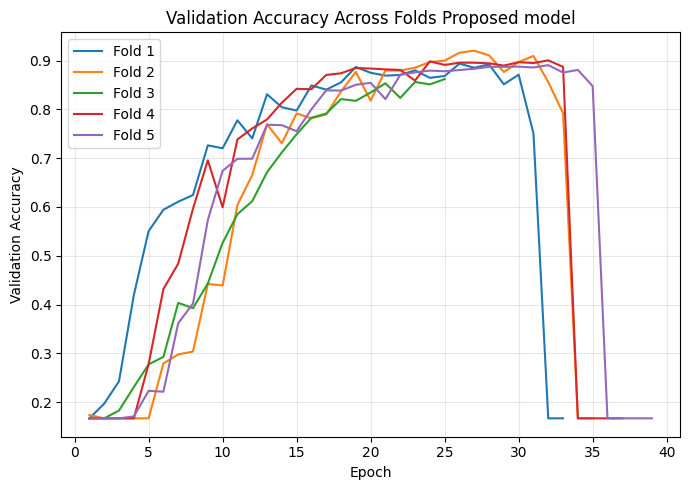

Results Directory: /home/faizaan/AD/projects/HandlingImbalance/Results/stage1_v2


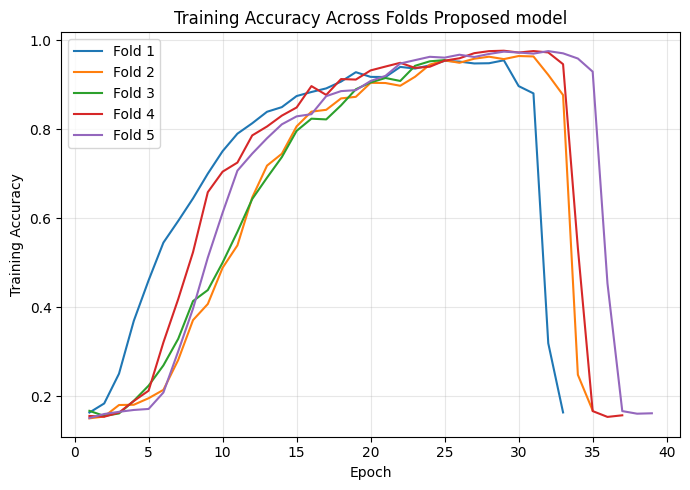

In [22]:
# =====================================================
# 📉 Plot Validation Loss Across Folds (Stage1_v2)
# =====================================================
import matplotlib.pyplot as plt

RESULTS_DIR = LOCAL_PROJECT_ROOT / "Results" / RESULTS_FOLDER

plt.figure(figsize=(7, 5))
for fold_idx in range(1, 6):
    hist_path = RESULTS_DIR / f"fold_{fold_idx}" / "history_stage1v2.csv"
    df_hist = pd.read_csv(hist_path)
    plt.plot(df_hist["epoch"], df_hist["val_acc"], label=f"Fold {fold_idx}")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy Across Folds Proposed model")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# =====================================================
# 📉 Plot Validation Loss Across Folds (Stage1_v2)
# =====================================================
import matplotlib.pyplot as plt

RESULTS_DIR = LOCAL_PROJECT_ROOT / "Results" / RESULTS_FOLDER
print(f"Results Directory: {RESULTS_DIR}")
plt.figure(figsize=(7, 5))
for fold_idx in range(1, 6):
    hist_path = RESULTS_DIR / f"fold_{fold_idx}" / "history_stage1v2.csv"
    df_hist = pd.read_csv(hist_path)
    plt.plot(df_hist["epoch"], df_hist["train_acc"], label=f"Fold {fold_idx}")

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.title("Training Accuracy Across Folds Proposed model")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



#### ROC 

Fold 1


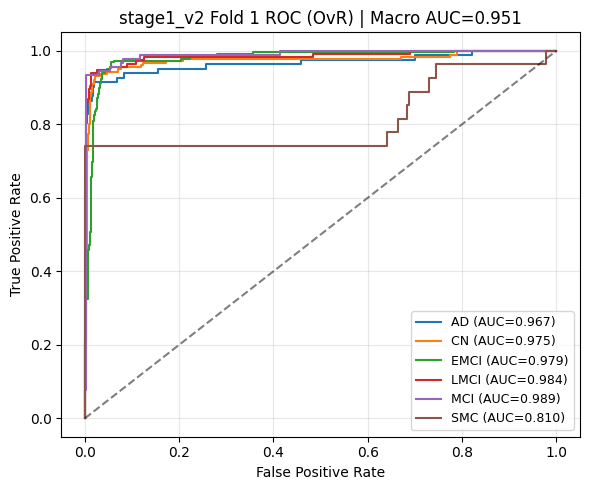

Fold 2


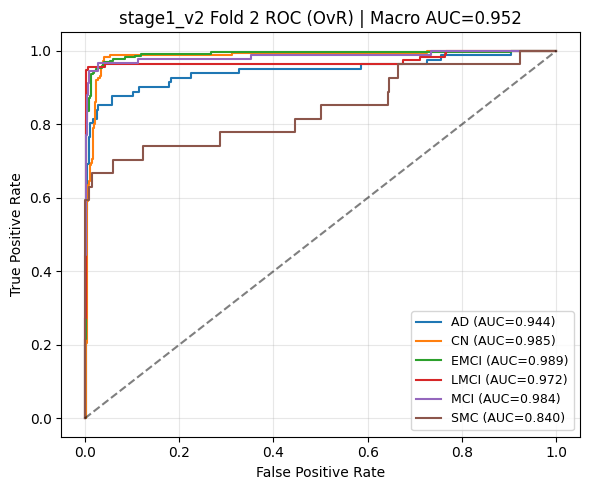

Fold 3


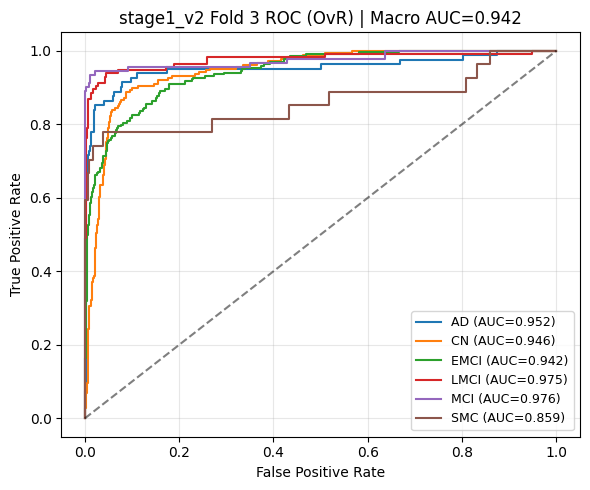

Fold 4


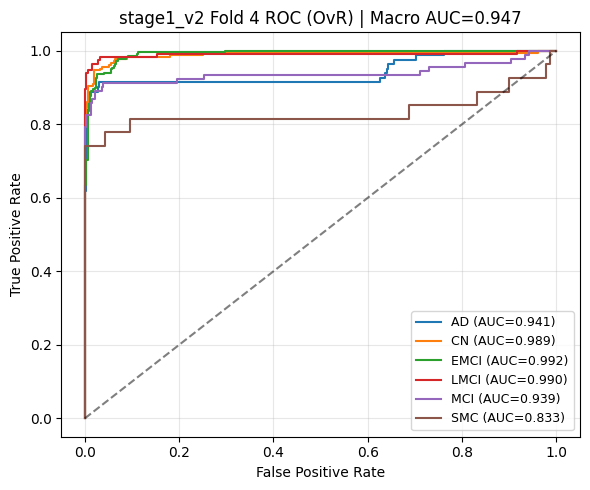

Fold 5


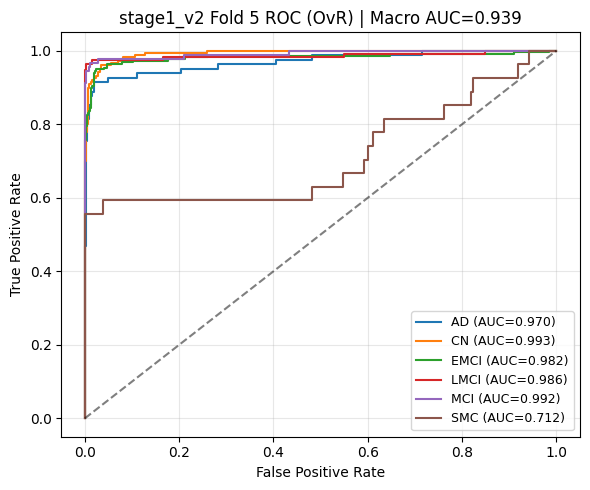

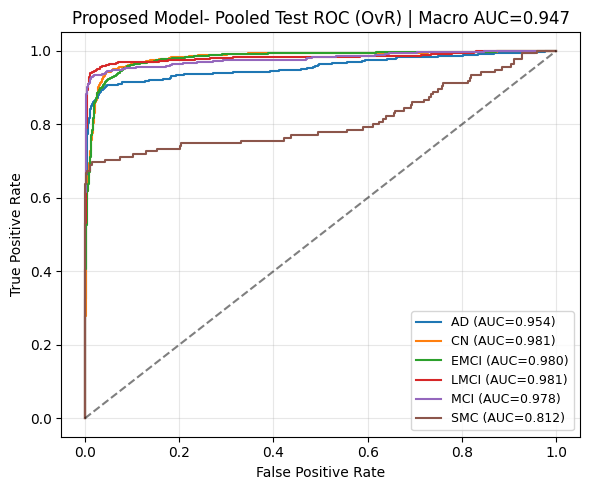

np.float64(0.9474025407559695)

In [30]:
# Collect per-sample test probs/labels and plot OvR ROC (macro AUC)
import numpy as np, pandas as pd, torch
from torch.utils.data import DataLoader
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from pathlib import Path

# --- Config ---
SPLIT_VERSION = "stage1_v2"  # legacy artifact filename suffix
RESULTS_FOLDER = "Proposed_Model"
MODEL_FILENAME = f"best_model_stage1v2.pt"
BATCH_SIZE = 2

LOCAL_PROJECT_ROOT = Path("/home/faizaan/AD/projects/HandlingImbalance")
RESULTS_DIR = LOCAL_PROJECT_ROOT / "Results" / RESULTS_FOLDER
SPLIT_DIR   = LOCAL_PROJECT_ROOT / "folds"


label_map    = {'AD':0, 'CN':1, 'EMCI':2, 'LMCI':3, 'MCI':4, 'SMC':5}
idx_to_label = {v: k for k, v in label_map.items()}
class_names  = [idx_to_label[i] for i in range(len(label_map))]

# --- Helper: plot OvR ROC ---
def plot_roc_ovr(all_labels, all_probs, class_names, title, out_path=None):
    fig, ax = plt.subplots(figsize=(6, 5))
    aucs = []
    for i, name in enumerate(class_names):
        y_true = (all_labels == i).astype(int)
        y_score = all_probs[:, i]
        fpr, tpr, _ = roc_curve(y_true, y_score)
        roc_auc = auc(fpr, tpr)
        aucs.append(roc_auc)
        ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"{title} | Macro AUC={np.mean(aucs):.3f}")
    ax.legend(loc="lower right", fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    if out_path:
        fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return np.mean(aucs)

# --- Collect per-fold probs/labels ---
all_labels_list, all_probs_list = [], []

for fold_idx in range(1, 6):
    print(f"Fold {fold_idx}")
    split_fold_dir  = SPLIT_DIR   / f"fold_{fold_idx}"
    result_fold_dir = RESULTS_DIR / f"fold_{fold_idx}"
    result_fold_dir.mkdir(parents=True, exist_ok=True)

    # Load data
    test_df = pd.read_csv(split_fold_dir / "test.csv")
    test_ds = MRIDataset(test_df, "BiasCorrPath", "GroupLabel")  # assumes MRIDataset is in scope
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                             num_workers=2, prefetch_factor=1)

    # Load model
    model = BetterEfficient3DEncoder(num_classes=len(label_map)).to(device)  # swap to ResNet3D18 if needed
    best_path = result_fold_dir / MODEL_FILENAME

    state = torch.load(best_path, map_location=device)
    if isinstance(state, dict) and "model" in state:
        model.load_state_dict(state["model"])
    else:
        model.load_state_dict(state)
    model.eval()

    # Gather probabilities/labels
    labels_fold, probs_fold = [], []
    with torch.no_grad():
        for b in test_loader:
            imgs = b["image"].to(device)
            lbl  = b["label"].to(device)
            with torch.amp.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(imgs)
                probs  = torch.softmax(logits, dim=1)
            labels_fold.append(lbl.cpu())
            probs_fold.append(probs.cpu())

    labels_fold = torch.cat(labels_fold, dim=0).numpy()
    probs_fold  = torch.cat(probs_fold,  dim=0).numpy()

    # Save per-fold probs/labels
    prob_df = pd.DataFrame(probs_fold, columns=[f"prob_{c}" for c in class_names])
    prob_df["true"] = labels_fold
    prob_df.to_csv(result_fold_dir / f"probs_fold_{fold_idx}.csv", index=False)

    # Per-fold ROC
    plot_roc_ovr(labels_fold, probs_fold, class_names,
                 title=f"{SPLIT_VERSION} Fold {fold_idx} ROC (OvR)",
                 out_path=result_fold_dir / f"roc_fold_{fold_idx}.png")

    all_labels_list.append(labels_fold)
    all_probs_list.append(probs_fold)

# --- Pooled ROC across folds ---
all_labels = np.concatenate(all_labels_list)
all_probs  = np.concatenate(all_probs_list)
plot_roc_ovr(all_labels, all_probs, class_names,
             title=f"Proposed Model- Pooled Test ROC (OvR)",
             out_path=RESULTS_DIR / "roc_pooled.png")


In [1]:
import copy, io, json, math, time, platform
from datetime import datetime, timezone
from pathlib import Path

# Exact architecture copied from original Cell 7 for architecture-only fallback profiling.
PROJECT_PROFILE_ROOT = Path("/media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM")
EXPECTED_PARAMETERS = 2_643_626

def run_complexity_profile():
    try:
        import torch
        import torch.nn as nn
        import numpy as np
        import pandas as pd
    except Exception as exc:
        print("Profiling dependencies unavailable:", exc)
        return

    class MultiScaleDWConv3D(nn.Module):
        def __init__(self, in_c, out_c, stride=1, k=3, dilation=2, gn_groups=8):
            super().__init__()
            pad = (k // 2) * dilation
            self.dw = nn.Conv3d(in_c, in_c, k, stride, pad, dilation=dilation, groups=in_c, bias=False)
            self.pw = nn.Conv3d(in_c, out_c, 1, bias=False)
            self.norm = nn.GroupNorm(num_groups=min(gn_groups, out_c), num_channels=out_c)
            self.act = nn.GELU()
        def forward(self, x):
            return self.act(self.norm(self.pw(self.dw(x))))

    class SEBlock3D(nn.Module):
        def __init__(self, channels, reduction=8):
            super().__init__()
            self.pool = nn.AdaptiveAvgPool3d(1)
            self.fc = nn.Sequential(
                nn.Linear(channels, max(1, channels // reduction)), nn.GELU(),
                nn.Linear(max(1, channels // reduction), channels), nn.Sigmoid()
            )
        def forward(self, x):
            b, c, _, _, _ = x.shape
            w = self.fc(self.pool(x).view(b, c)).view(b, c, 1, 1, 1)
            return x * w

    class StochasticDepth3D(nn.Module):
        def __init__(self, p=0.0):
            super().__init__()
            self.p = p
        def forward(self, x):
            if not self.training or self.p == 0:
                return x
            keep = 1 - self.p
            mask = x.new_empty((x.shape[0], 1, 1, 1, 1)).bernoulli_(keep)
            return x * mask / keep

    class BetterResBlock3D(nn.Module):
        def __init__(self, in_c, out_c, stride=1, se_ratio=0.25, drop_path=0.1, spatial_drop=0.1):
            super().__init__()
            self.use_proj = (stride != 1) or (in_c != out_c)
            self.ms1 = MultiScaleDWConv3D(in_c, out_c, stride=stride, dilation=2)
            self.ms2 = MultiScaleDWConv3D(out_c, out_c)
            self.mlp = nn.Sequential(
                nn.Conv3d(out_c, out_c * 4, 1),
                nn.GELU(),
                nn.Conv3d(out_c * 4, out_c, 1),
                nn.Dropout3d(spatial_drop)
            )
            self.se = SEBlock3D(out_c, reduction=max(1, int(out_c * se_ratio)))
            self.drop = StochasticDepth3D(drop_path)
            self.proj = nn.Conv3d(in_c, out_c, 1, stride=stride, bias=False) if self.use_proj else nn.Identity()
        def forward(self, x):
            idn = self.proj(x)
            x = self.ms2(self.ms1(x))
            x = self.mlp(x)
            x = self.se(x)
            x = self.drop(x)
            return idn + x

    class BetterEfficient3DEncoder(nn.Module):
        def __init__(self, in_channels=1, base_channels=32, num_classes=6, drop_path_rate=0.2, spatial_drop=0.1):
            super().__init__()
            self.stem = nn.Sequential(
                nn.Conv3d(in_channels, base_channels, 3, 2, 1, bias=False),
                nn.GroupNorm(num_groups=min(8, base_channels), num_channels=base_channels),
                nn.GELU()
            )
            widths = [base_channels, base_channels * 2, base_channels * 4, base_channels * 8]
            strides = [1, 2, 2, 2]
            n_blocks = [2, 2, 2, 3]
            total_blocks = sum(n_blocks)
            dp_rates = torch.linspace(0.05, drop_path_rate, total_blocks).tolist()
            blocks = []
            in_c = widths[0]
            idx = 0
            for out_c, stride, block_count in zip(widths, strides, n_blocks):
                for block_index in range(block_count):
                    blocks.append(BetterResBlock3D(
                        in_c, out_c,
                        stride=stride if block_index == 0 else 1,
                        drop_path=dp_rates[idx],
                        spatial_drop=spatial_drop
                    ))
                    in_c = out_c
                    idx += 1
            self.encoder = nn.Sequential(*blocks)
            self.encoder_dropout = nn.Dropout3d(0.05)
            self.gap = nn.AdaptiveAvgPool3d(1)
            self.gmp = nn.AdaptiveMaxPool3d(1)
            self.classifier = nn.Sequential(
                nn.Flatten(),
                nn.Linear(widths[-1] * 2, widths[-1]), nn.GELU(),
                nn.Dropout(0.20),
                nn.Linear(widths[-1], widths[-1] // 2), nn.GELU(),
                nn.Dropout(0.20),
                nn.Linear(widths[-1] // 2, num_classes)
            )
        def forward(self, x):
            x = self.stem(x)
            x = self.encoder(x)
            x = self.encoder_dropout(x)
            feat = torch.cat([self.gap(x), self.gmp(x)], 1)
            return self.classifier(feat)

    ns = globals()
    names = ["best_model", "model", "net", "classifier"]
    candidates = [(n, ns[n]) for n in names if n in ns and isinstance(ns[n], nn.Module)]
    valid_candidates = [(name, obj) for name, obj in candidates if sum(p.numel() for p in obj.parameters()) == EXPECTED_PARAMETERS]
    if torch.cuda.is_available():
        # This project reserves GPU 0; use GPU 2 when present, otherwise GPU 1.
        profile_gpu = 2 if torch.cuda.device_count() > 2 else (1 if torch.cuda.device_count() > 1 else 0)
        device = torch.device(f"cuda:{profile_gpu}")
    else:
        device = torch.device("cpu")
    if valid_candidates:
        model_name, model_object = next(((n, o) for n, o in valid_candidates if n == "best_model"), valid_candidates[0])
        profile_model = copy.deepcopy(model_object).to(device)
        architecture_source = f"Valid live model object: {model_name}"
        print("Valid live model object found:", model_name)
    else:
        profile_model = BetterEfficient3DEncoder(
            in_channels=1,
            base_channels=32,
            num_classes=6,
            drop_path_rate=0.2,
            spatial_drop=0.1
        ).to(device)
        architecture_source = "Exact architecture copied from original Cell 7"
        print("No valid live model object was available.")
        print("Instantiated the exact finalized Proposed architecture locally for profiling only.")
    print("Architecture source:", architecture_source)
    print("Profiling device:", device)
    dummy = train_x = train_y = None
    try:
        profile_model.eval()
        cuda = device.type == "cuda" and torch.cuda.is_available()
        total = int(sum(p.numel() for p in profile_model.parameters()))
        print("EXPECTED PARAMETERS: 2,643,626")
        print(f"OBSERVED PARAMETERS: {total:,}")
        if total != EXPECTED_PARAMETERS:
            print("ARCHITECTURE INTEGRITY CHECK FAILED.")
            print("Profiling results were NOT generated.")
            print("ORIGINAL CELLS MODIFIED: NO")
            print("ORIGINAL CELLS EXECUTED: NO")
            print("ORIGINAL OUTPUTS CLEARED: NO")
            print("TRAINING EXECUTED: NO")
            print("VALIDATION EXECUTED: NO")
            print("DATASET TEST INFERENCE EXECUTED: NO")
            print("CHECKPOINT LOADED: NO")
            return
        print("ARCHITECTURE INTEGRITY CHECK: PASSED")
        dummy = torch.zeros((1, 1, 128, 128, 128), dtype=torch.float32, device=device)
        def logits(value):
            if isinstance(value, torch.Tensor): return value
            if isinstance(value, dict):
                for key in ("logits", "output", "out"):
                    if isinstance(value.get(key), torch.Tensor): return value[key]
                return next((x for x in value.values() if isinstance(x, torch.Tensor)), None)
            if isinstance(value, (tuple, list)):
                return next((x for x in value if isinstance(x, torch.Tensor)), None)
            return None
        with torch.inference_mode():
            sanity = logits(profile_model(dummy))
        if sanity is None or tuple(sanity.shape) != (1, 6):
            print("SYNTHETIC FORWARD CHECK FAILED; expected output shape (1, 6).")
            print("Observed output:", None if sanity is None else tuple(sanity.shape))
            print("Profiling results were NOT generated.")
            return
        print("SYNTHETIC FORWARD CHECK: PASSED")
        print("Synthetic output shape:", tuple(sanity.shape))
        trainable = int(sum(p.numel() for p in profile_model.parameters() if p.requires_grad))
        param_mib = total * 4 / 1024**2
        buf = io.BytesIO(); torch.save(profile_model.state_dict(), buf)
        state_mib = buf.tell() / 1024**2
        count = {"macs": 0.0}; hooks = []
        def conv_hook(layer, inp, out):
            out = logits(out)
            if out is not None:
                count["macs"] += out.numel() * math.prod(layer.kernel_size) * layer.in_channels / layer.groups
        def linear_hook(layer, inp, out):
            out = logits(out)
            if out is not None: count["macs"] += out.numel() * layer.in_features
        for layer in profile_model.modules():
            if isinstance(layer, nn.Conv3d): hooks.append(layer.register_forward_hook(conv_hook))
            elif isinstance(layer, nn.Linear): hooks.append(layer.register_forward_hook(linear_hook))
        try:
            with torch.inference_mode(): logits(profile_model(dummy))
        finally:
            for hook in hooks: hook.remove()
        macs = float(count["macs"]); flops = 2.0 * macs
        alloc = reserved = None
        latencies = []
        if cuda:
            torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(device); torch.cuda.synchronize(device)
            with torch.inference_mode(): logits(profile_model(dummy))
            torch.cuda.synchronize(device)
            alloc = torch.cuda.max_memory_allocated(device) / 1024**2
            reserved = torch.cuda.max_memory_reserved(device) / 1024**2
            for _ in range(10):
                with torch.inference_mode(): logits(profile_model(dummy))
            torch.cuda.synchronize(device)
            for _ in range(50):
                start, end = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
                start.record()
                with torch.inference_mode(): logits(profile_model(dummy))
                end.record(); end.synchronize(); latencies.append(float(start.elapsed_time(end)))
        else:
            print("CUDA is unavailable; using CPU wall-clock timing.")
            for _ in range(10):
                with torch.inference_mode(): logits(profile_model(dummy))
            for _ in range(50):
                t0 = time.perf_counter()
                with torch.inference_mode(): logits(profile_model(dummy))
                latencies.append((time.perf_counter() - t0) * 1000)
        latencies = np.asarray(latencies, dtype=float)
        mean_ms, sd_ms = float(latencies.mean()), float(latencies.std(ddof=1))
        median_ms, p95_ms = float(np.median(latencies)), float(np.percentile(latencies, 95))
        min_ms, max_ms = float(latencies.min()), float(latencies.max())
        throughput = 1000 / mean_ms if mean_ms > 0 else None
        train_alloc = train_reserved = None
        if cuda:
            try:
                profile_model.train()
                train_x = torch.zeros((1, 1, 128, 128, 128), dtype=torch.float32, device=device)
                train_y = torch.zeros((1,), dtype=torch.long, device=device)
                torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(device); profile_model.zero_grad(set_to_none=True)
                loss = nn.CrossEntropyLoss()(logits(profile_model(train_x)), train_y); loss.backward(); torch.cuda.synchronize(device)
                train_alloc = torch.cuda.max_memory_allocated(device) / 1024**2
                train_reserved = torch.cuda.max_memory_reserved(device) / 1024**2
            except Exception as exc:
                print("Synthetic forward+backward peak memory: NOT AVAILABLE", exc)
                torch.cuda.empty_cache()
            finally:
                profile_model.eval()
        # Inspect active Proposed-model histories only; never inspect archives.
        active_results_dir = PROJECT_PROFILE_ROOT / "Results" / "Proposed_Model"
        history_files = sorted(active_results_dir.glob("fold_*/history_stage1v2.csv"))
        history_files = sorted(set(history_files)); timing = []; timing_sources = []
        timing_columns = ("epoch_time_sec", "epoch_seconds", "duration_sec", "time_sec", "train_time_sec", "elapsed_seconds", "elapsed_minutes")
        for path in history_files:
            frame = pd.read_csv(path); matches = [c for c in timing_columns if c in frame.columns]
            if matches:
                column = matches[0]; values = pd.to_numeric(frame[column], errors="coerce").dropna().to_numpy(float)
                if column == "elapsed_minutes": values *= 60
                timing += values.tolist(); timing_sources.append(str(path))
        if timing:
            timing = np.asarray(timing, dtype=float); epoch_mean = float(timing.mean()); epoch_sd = float(timing.std(ddof=1)) if len(timing) > 1 else 0.0; train_time = float(timing.sum())
            timing_note = "Exact timing columns read from saved history CSV files."
        else:
            epoch_mean = epoch_sd = train_time = None
            timing_note = "Training time was not recorded in the available history files and was not retrospectively estimated."
        if cuda:
            gpu = torch.cuda.get_device_name(device); cuda_version = torch.version.cuda; gpu_index = device.index; total_gpu_mib = torch.cuda.get_device_properties(device).total_memory / 1024**2
        else:
            gpu, cuda_version, gpu_index, total_gpu_mib = "CUDA unavailable", torch.version.cuda, None, None
        out = PROJECT_PROFILE_ROOT / "Results" / "Analysis" / "Complexity_Runtime" / "Proposed_3D_CNN"; out.mkdir(parents=True, exist_ok=True)
        stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
        def path_for(name):
            p = out / name
            if not p.exists():
                return p
            candidate = out / f"{p.stem}_{stamp}{p.suffix}"
            counter = 1
            while candidate.exists():
                candidate = out / f"{p.stem}_{stamp}_{counter}{p.suffix}"
                counter += 1
            return candidate
        output_paths = {
            "summary_csv": path_for("complexity_runtime_summary.csv"),
            "summary_json": path_for("complexity_runtime_summary.json"),
            "latency_csv": path_for("inference_latency_raw_ms.csv"),
            "environment_json": path_for("complexity_runtime_environment.json"),
        }
        summary = {
            "Profiling_Label": "Architecture-level FP32 profiling of the finalized Proposed 3D CNN",
            "Model": "Proposed 3D CNN", "Model_Class": type(profile_model).__name__, "Architecture_Source": architecture_source,
            "Expected_Parameters": EXPECTED_PARAMETERS, "Architecture_Integrity_Check": "PASS",
            "Trained_Weights_Loaded": False, "Checkpoint_Loaded": False,
            "Input_Shape": "(1, 1, 128, 128, 128)", "Batch_Size": 1, "Precision": "FP32",
            "Total_Parameters": total, "Trainable_Parameters": trainable, "Parameter_Memory_MiB": param_mib, "Serialized_StateDict_MiB": state_mib,
            "MACs": macs, "Approx_FLOPs": flops, "Inference_Mean_ms_per_MRI": mean_ms, "Inference_SD_ms": sd_ms, "Inference_Median_ms": median_ms,
            "Inference_P95_ms": p95_ms, "Inference_Min_ms": min_ms, "Inference_Max_ms": max_ms, "Inference_Throughput_MRI_per_s": throughput,
            "Inference_Peak_Allocated_MiB": alloc, "Inference_Peak_Reserved_MiB": reserved, "Training_Peak_Allocated_MiB_if_profiled": train_alloc,
            "Training_Peak_Reserved_MiB_if_profiled": train_reserved, "Mean_Epoch_Time_if_logged": epoch_mean, "SD_Epoch_Time_if_logged": epoch_sd,
            "Total_Training_Time_if_logged": train_time, "GPU": gpu, "CUDA_Device_Index": gpu_index, "Total_GPU_Memory_MiB": total_gpu_mib,
            "PyTorch": torch.__version__, "CUDA": cuda_version, "Training_Time_Note": timing_note,
            "History_Source_Files": timing_sources or [str(p) for p in history_files],
            "MAC_Convention": "One MAC is approximately two FLOPs; Conv3d and Linear only.",
        }
        pd.DataFrame([summary]).to_csv(output_paths["summary_csv"], index=False)
        output_paths["summary_json"].write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
        pd.DataFrame({"latency_ms": latencies}).to_csv(output_paths["latency_csv"], index=False)
        environment = {"Profiling_Label": summary["Profiling_Label"], "GPU": gpu, "CUDA_Device_Index": gpu_index, "CUDA": cuda_version, "Total_GPU_Memory_MiB": total_gpu_mib, "PyTorch": torch.__version__, "Python": platform.python_version(), "Input_Shape": [1, 1, 128, 128, 128], "Batch_Size": 1, "Precision": "FP32", "Warmup_Runs": 10, "Timed_Runs": 50, "Runtime_Excludes": "MRI preprocessing and disk I/O", "Trained_Weights_Loaded": False}
        output_paths["environment_json"].write_text(json.dumps(environment, indent=2, default=str), encoding="utf-8")
        print("ORIGINAL CELLS MODIFIED: NO")
        print("ORIGINAL CELLS EXECUTED: NO")
        print("ORIGINAL OUTPUTS CLEARED: NO")
        print("TRAINING EXECUTED: NO")
        print("VALIDATION EXECUTED: NO")
        print("DATASET TEST INFERENCE EXECUTED: NO")
        print("CHECKPOINT LOADED: NO")
        print("\nARCHITECTURE SOURCE:")
        print("Exact architecture copied from original Cell 7")
        print("\nEXPECTED PARAMETERS:")
        print("2,643,626")
        print("\nOBSERVED PARAMETERS:")
        print(f"{total:,}")
        print("\nARCHITECTURE INTEGRITY CHECK:")
        print("PASS")
        print("\n==================================================")
        print("Architecture-level FP32 profiling of the finalized Proposed 3D CNN")
        print("==================================================")
        print("Model:", summary["Model"]); print("Model class:", summary["Model_Class"]); print("Input:", summary["Input_Shape"]); print("Precision:", summary["Precision"]); print("GPU:", summary["GPU"])
        print("\nTotal parameters:", total); print("Trainable parameters:", trainable); print("Serialized state_dict size:", f"{state_mib:.3f} MiB"); print("Parameter memory:", f"{param_mib:.3f} MiB")
        print("\nMACs / MRI:", f"{macs:.0f}"); print("Approximate FLOPs / MRI:", f"{flops:.0f}", "(one MAC is approximately two FLOPs; Conv3d/Linear only)")
        print("\nFP32 inference, batch size 1:"); print("Mean latency:", f"{mean_ms:.4f} ms/MRI"); print("SD:", f"{sd_ms:.4f} ms"); print("Median:", f"{median_ms:.4f} ms"); print("P95:", f"{p95_ms:.4f} ms"); print("Throughput:", f"{throughput:.4f} MRI/s")
        print("\nInference peak allocated GPU memory:", "NOT AVAILABLE" if alloc is None else f"{alloc:.3f} MiB"); print("Inference peak reserved GPU memory:", "NOT AVAILABLE" if reserved is None else f"{reserved:.3f} MiB")
        print("\nSynthetic forward+backward peak allocated memory:", "NOT AVAILABLE" if train_alloc is None else f"{train_alloc:.3f} MiB"); print("Synthetic forward+backward peak reserved memory:", "NOT AVAILABLE" if train_reserved is None else f"{train_reserved:.3f} MiB")
        print("\nSaved training-time information:"); print("Mean epoch time:", "NOT AVAILABLE" if epoch_mean is None else f"{epoch_mean:.4f} s"); print("SD:", "NOT AVAILABLE" if epoch_sd is None else f"{epoch_sd:.4f} s"); print("Mean/total training time:", "NOT AVAILABLE" if train_time is None else f"{train_time:.4f} s"); print("Source history file(s) inspected:", [str(p) for p in history_files]); print(timing_note)
        print("\nIMPORTANT INTERPRETATION:")
        print("- Runtime excludes MRI preprocessing and disk I/O."); print("- Inference uses batch size 1."); print("- FLOPs use the explicit Conv3d/Linear counting convention."); print("- Training time is reported only if present in existing logs."); print("- No training, validation, or dataset-level inference was run."); print("- No checkpoint or trained weights were loaded; learned values are not required for graph-level profiling.")
        print("\nOutput directory:", out.resolve())
        print("Output files:")
        for output_path in output_paths.values():
            print(output_path.resolve())
        print("==================================================")
    except Exception as exc:
        print("Profiling cell stopped gracefully:", type(exc).__name__, exc)
    finally:
        for obj in ("train_x", "train_y", "dummy", "profile_model"):
            if obj in locals() and locals()[obj] is not None:
                del locals()[obj]
        if "torch" in locals() and torch.cuda.is_available(): torch.cuda.empty_cache()

run_complexity_profile()


No valid live model object was available.
Instantiated the exact finalized Proposed architecture locally for profiling only.
Architecture source: Exact architecture copied from original Cell 7
Profiling device: cuda:2
EXPECTED PARAMETERS: 2,643,626
OBSERVED PARAMETERS: 2,643,626
ARCHITECTURE INTEGRITY CHECK: PASSED
SYNTHETIC FORWARD CHECK: PASSED
Synthetic output shape: (1, 6)
ORIGINAL CELLS MODIFIED: NO
ORIGINAL CELLS EXECUTED: NO
ORIGINAL OUTPUTS CLEARED: NO
TRAINING EXECUTED: NO
VALIDATION EXECUTED: NO
DATASET TEST INFERENCE EXECUTED: NO
CHECKPOINT LOADED: NO

ARCHITECTURE SOURCE:
Exact architecture copied from original Cell 7

EXPECTED PARAMETERS:
2,643,626

OBSERVED PARAMETERS:
2,643,626

ARCHITECTURE INTEGRITY CHECK:
PASS

Architecture-level FP32 profiling of the finalized Proposed 3D CNN
Model: Proposed 3D CNN
Model class: BetterEfficient3DEncoder
Input: (1, 1, 128, 128, 128)
Precision: FP32
GPU: NVIDIA GeForce RTX 3090

Total parameters: 2643626
Trainable parameters: 2643626
Se